# Module 08, Part 1: The adversarial game

This notebook is the runnable companion to Part 1 of the Module 08 learning content. It checks, with code:

1. What the best possible discriminator is, by training one in one dimension and comparing it with the formula.
2. That the value of the game at that discriminator is a measure of how far the generator's distribution is from the data.
3. Why the original generator loss stops teaching when the discriminator is winning, by measuring the gradient the generator receives.
4. A first GAN trained on eight Gaussians arranged in a ring, with a count of how many of the eight it learned.

Everything runs on a CPU in a few minutes.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import math
import numpy as np
import torch


def ring_of_gaussians(n, n_modes=8, radius=2.0, std=0.05, seed=0):
    """n points from a mixture of n_modes Gaussians evenly spaced on a circle. Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, n_modes, (n,), generator=g)
    ang = 2 * math.pi * k.float() / n_modes
    centers = radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)
    return centers + std * torch.randn(n, 2, generator=g), k


def mode_centers(n_modes=8, radius=2.0):
    ang = 2 * math.pi * torch.arange(n_modes).float() / n_modes
    return radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)


def mode_coverage(samples, n_modes=8, radius=2.0, std=0.05, tol=6.0):
    """Return (modes covered, share of samples within tol*std of a mode centre).
    A mode counts as covered if at least 1 percent of the samples land near it."""
    c = mode_centers(n_modes, radius)
    d = torch.cdist(samples, c)
    near = d.min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=n_modes)
    return int((counts >= 0.01 * len(samples)).sum()), float(ok.float().mean())


def grid_centers(side=5, spacing=1.0):
    r = (torch.arange(side).float() - (side - 1) / 2) * spacing
    return torch.stack(torch.meshgrid(r, r, indexing="ij"), -1).reshape(-1, 2)


def grid_of_gaussians(n, side=5, spacing=1.0, std=0.05, seed=0):
    """n points from a side-by-side grid of Gaussians (25 modes for side=5). Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    c = grid_centers(side, spacing)
    k = torch.randint(0, len(c), (n,), generator=g)
    return c[k] + std * torch.randn(n, 2, generator=g), k


def grid_coverage(samples, side=5, spacing=1.0, std=0.05, tol=6.0):
    """(modes covered, share of samples within tol*std of a mode centre); a mode counts if it holds at least 0.4 percent of the samples."""
    c = grid_centers(side, spacing)
    near = torch.cdist(samples, c).min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=len(c))
    return int((counts >= 0.2 / len(c) * len(samples)).sum()), float(ok.float().mean())

In [3]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(d_in, d_out, d_hidden=64, layers=2, act=nn.ReLU, spectral=False):
    mods, d = [], d_in
    for _ in range(layers):
        lin = nn.Linear(d, d_hidden)
        mods += [nn.utils.spectral_norm(lin) if spectral else lin, act()]
        d = d_hidden
    last = nn.Linear(d, d_out)
    mods.append(nn.utils.spectral_norm(last) if spectral else last)
    return nn.Sequential(*mods)


class Generator(nn.Module):
    """Maps noise (and an optional one-hot label) to a sample. out_act='sigmoid' for images in [0, 1], None for raw coordinates."""

    def __init__(self, d_noise=8, d_out=2, d_hidden=64, n_classes=0, out_act=None):
        super().__init__()
        self.d_noise, self.n_classes = d_noise, n_classes
        self.net = mlp(d_noise + n_classes, d_out, d_hidden)
        self.out_act = out_act

    def forward(self, z, c=None):
        out = self.net(z if c is None else torch.cat([z, c], 1))
        return torch.sigmoid(out) if self.out_act == "sigmoid" else out


class Discriminator(nn.Module):
    """Returns a logit (a real-valued score for the Wasserstein critic). With n_classes > 0 it also sees the label."""

    def __init__(self, d_in=2, d_hidden=64, n_classes=0, spectral=False):
        super().__init__()
        self.net = mlp(d_in + n_classes, 1, d_hidden, act=lambda: nn.LeakyReLU(0.2), spectral=spectral)

    def forward(self, x, c=None):
        return self.net(x if c is None else torch.cat([x, c], 1)).squeeze(1)


def gradient_penalty(D, real, fake, c=None):
    """WGAN-GP: penalize the critic's gradient norm, measured on random points between real and fake, for deviating from 1."""
    t = torch.rand(len(real), 1)
    x = (t * real + (1 - t) * fake).requires_grad_(True)
    g, = torch.autograd.grad(D(x, c).sum(), x, create_graph=True)
    return ((g.norm(dim=1) - 1) ** 2).mean(), g.norm(dim=1).mean().item()


def train_gan(G, D, X, y_onehot=None, objective="nonsat", steps=2000, batch_size=128, lr_g=2e-3, lr_d=2e-3,
              n_critic=1, gp_weight=10.0, seed=0, betas=(0.5, 0.9), log_every=0):
    """Alternate discriminator and generator updates.
    objective: 'minimax'  generator minimizes log(1 - D(G(z)))   (the original, saturating loss)
               'nonsat'   generator maximizes log D(G(z))        (the standard fix)
               'wgan_gp'  critic maximizes D(real) - D(fake) with a gradient penalty, generator maximizes D(G(z))
    Returns a dict of histories: d_loss, g_loss, d_real (mean probability or score on real), d_fake, g_grad (norm of the loss gradient at the generator output)."""
    torch.manual_seed(seed)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    h = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": [], "g_grad": [], "gp_norm": []}
    n = len(X)
    for step in range(steps):
        for _ in range(n_critic):
            idx = torch.randint(0, n, (batch_size,))
            real = X[idx]
            c = None if y_onehot is None else y_onehot[idx]
            with torch.no_grad():
                fake = G(torch.randn(batch_size, G.d_noise), c)
            dr, df = D(real, c), D(fake, c)
            if objective == "wgan_gp":
                gp, gpn = gradient_penalty(D, real, fake, c)
                d_loss = df.mean() - dr.mean() + gp_weight * gp
                h["gp_norm"].append(gpn)
            else:
                d_loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + \
                         F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        idx = torch.randint(0, n, (batch_size,))
        c = None if y_onehot is None else y_onehot[idx]
        fake = G(torch.randn(batch_size, G.d_noise), c)
        fake.retain_grad()
        df = D(fake, c)
        if objective == "minimax":
            g_loss = -F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))   # = log(1 - D(G(z)))
        elif objective == "nonsat":
            g_loss = F.binary_cross_entropy_with_logits(df, torch.ones_like(df))     # = -log D(G(z))
        else:
            g_loss = -df.mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        h["d_loss"].append(float(d_loss.detach())); h["g_loss"].append(float(g_loss.detach()))
        h["g_grad"].append(float(fake.grad.norm(dim=1).mean()))
        if objective == "wgan_gp":
            h["d_real"].append(float(dr.mean().detach())); h["d_fake"].append(float(df.mean().detach()))
        else:
            h["d_real"].append(float(torch.sigmoid(dr).mean().detach())); h["d_fake"].append(float(torch.sigmoid(df).mean().detach()))
    return h


@torch.no_grad()
def sample_gan(G, n, seed=0, label=None):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, G.d_noise, generator=g)
    c = None if G.n_classes == 0 else torch.nn.functional.one_hot(torch.full((n,), label), G.n_classes).float()
    return G(z, c)

## 1. The best discriminator, from the formula and from training

The discriminator is trained to output the probability that its input is real. If real data has density $p_{\text{data}}$ and the generator's samples
have density $p_g$, the discriminator that is best at this job is

$$D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_g(x)}.$$

We check this with two Gaussians whose densities we know exactly: real data from $\mathcal{N}(0, 1)$ and a fixed "generator" that produces $\mathcal{N}(1.5, 1)$.
We train a small network as the discriminator and compare it with the formula over a grid of inputs.

In [4]:
def normal_pdf(x, m, s):
    return torch.exp(-0.5 * ((x - m) / s) ** 2) / (s * math.sqrt(2 * math.pi))

torch.manual_seed(0)
disc = mlp(1, 1, 32)
opt = torch.optim.Adam(disc.parameters(), lr=3e-3)
for step in range(3000):
    real = torch.randn(256, 1)
    fake = torch.randn(256, 1) + 1.5
    loss = F.binary_cross_entropy_with_logits(disc(real), torch.ones(256, 1)) + \
           F.binary_cross_entropy_with_logits(disc(fake), torch.zeros(256, 1))
    opt.zero_grad(); loss.backward(); opt.step()

xs = torch.linspace(-3, 4, 200)[:, None]
learned = torch.sigmoid(disc(xs)).detach().squeeze()
pd, pg = normal_pdf(xs.squeeze(), 0.0, 1.0), normal_pdf(xs.squeeze(), 1.5, 1.0)
formula = pd / (pd + pg)
inner = (xs.squeeze() > -2) & (xs.squeeze() < 3.5)
print(f"largest gap between the trained discriminator and the formula on [-2, 3.5]: {(learned - formula)[inner].abs().max():.3f}")

largest gap between the trained discriminator and the formula on [-2, 3.5]: 0.026


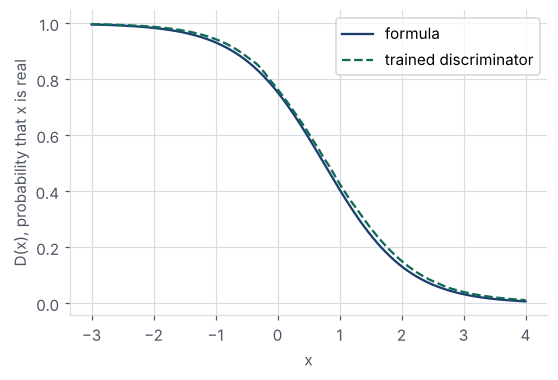

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.plot(xs.squeeze(), formula, color=NAVY, label="formula")
ax.plot(xs.squeeze(), learned, "--", color=GREEN, label="trained discriminator")
ax.set_xlabel("x"); ax.set_ylabel("D(x), probability that x is real"); ax.legend()
plt.show()

The trained discriminator follows the formula closely where there is data, and drifts only in the tails where it never saw a sample. The formula carries the
whole logic of the game: where the generator puts mass that the data does not, $D^*$ drops below one half, and that is the signal the generator uses.

## 2. The value of the game is a distance

At the best discriminator, the value of the minimax objective $V(D^*, G) = \mathbb{E}_{p_{\text{data}}}[\log D^*] + \mathbb{E}_{p_g}[\log(1 - D^*)]$ equals
$-\log 4 + 2\,\text{JS}(p_{\text{data}} \,\|\, p_g)$, where JS is the Jensen-Shannon divergence. So a generator that minimizes the game is minimizing a distance between distributions.
We confirm this by integrating both sides on a grid for generators at increasing distance from the data.

In [6]:
def value_at_best_d(shift):
    x = torch.linspace(-12, 12, 200001, dtype=torch.float64)
    pd, pg = normal_pdf(x, 0.0, 1.0), normal_pdf(x, shift, 1.0)
    dx = (x[1] - x[0]).item()
    v = (pd * torch.log(pd / (pd + pg)) + pg * torch.log(pg / (pd + pg))).sum() * dx
    m = 0.5 * (pd + pg)
    js = 0.5 * ((pd * torch.log(pd / m)).sum() + (pg * torch.log(pg / m)).sum()) * dx
    return v.item(), (-math.log(4) + 2 * js).item(), js.item()

print(" shift    V(D*, G)    -log4 + 2 JS    JS")
for s in [0.0, 0.5, 1.5, 3.0, 6.0]:
    v, rhs, js = value_at_best_d(s)
    print(f"{s:5.1f}   {v:9.4f}   {rhs:12.4f}   {js:.4f}")
print(f"\nJS can never exceed log 2 = {math.log(2):.4f}, however far apart the distributions are.")

 shift    V(D*, G)    -log4 + 2 JS    JS
  0.0     -1.3863        -1.3863   0.0000
  0.5     -1.3257        -1.3257   0.0303
  1.5     -0.9440        -0.9440   0.2212
  3.0     -0.3327        -0.3327   0.5268
  6.0     -0.0077        -0.0077   0.6893

JS can never exceed log 2 = 0.6931, however far apart the distributions are.


The two columns agree. The last line is the part to remember: the Jensen-Shannon divergence stops growing once the two distributions barely overlap, so it
stops telling the generator which way to move. The next section measures what that does to the gradient.

## 3. Saturation: the original loss stops teaching

The original generator loss is $\log(1 - D(G(z)))$, which the generator minimizes. Its alternative, the non-saturating loss, is $-\log D(G(z))$.
Both push the same way, but their gradients differ in size. With $s$ the discriminator's logit for a generated point, the gradient of the first with respect to $s$ is
$-\sigma(s)$ and of the second is $-(1 - \sigma(s))$, so when the discriminator is confident the sample is fake ($\sigma(s) \approx 0$), the first is almost zero and the second is near one.

We test this on a generator that starts far from the data. We train the discriminator against it until it wins, then measure the norm of the gradient each loss sends to the generator's output.

In [7]:
X, _ = ring_of_gaussians(5000)
torch.manual_seed(0)
G = Generator(d_noise=8, d_out=2)
with torch.no_grad():
    G.net[-1].bias += torch.tensor([6.0, 6.0])      # a generator that starts far from the ring
D = Discriminator()
opt_d = torch.optim.Adam(D.parameters(), lr=2e-3, betas=(0.5, 0.9))
for step in range(300):
    real = X[torch.randint(0, len(X), (128,))]
    with torch.no_grad():
        fake = G(torch.randn(128, 8))
    dr, df = D(real), D(fake)
    loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
    opt_d.zero_grad(); loss.backward(); opt_d.step()

fake = G(torch.randn(1000, 8)).detach().requires_grad_(True)
logit = D(fake)
for name, loss_fn in [("minimax: log(1 - D(G(z)))", lambda l: -F.binary_cross_entropy_with_logits(l, torch.zeros_like(l), reduction="sum")),
                      ("non-saturating: -log D(G(z))", lambda l: F.binary_cross_entropy_with_logits(l, torch.ones_like(l), reduction="sum"))]:
    g, = torch.autograd.grad(loss_fn(logit), fake, retain_graph=True)
    print(f"{name:32s} mean gradient norm at the generator output: {g.norm(dim=1).mean():.5f}")
print(f"mean D(G(z)) = {torch.sigmoid(logit).mean():.5f}")

minimax: log(1 - D(G(z)))        mean gradient norm at the generator output: 0.00000
non-saturating: -log D(G(z))     mean gradient norm at the generator output: 5.83478
mean D(G(z)) = 0.00000


When the discriminator is winning, the original loss sends a gradient that is orders of magnitude smaller than the non-saturating one. A generator that has fallen behind learns the slowest at exactly the moment it needs to learn the most.
This is why almost every implementation uses the non-saturating loss, and why we use it by default below.

## 4. A first GAN on eight Gaussians

Now the full game. The data is 5,000 points from eight Gaussians (standard deviation 0.05) on a circle of radius 2. The generator maps eight noise values to a point, the discriminator is a small network,
and we alternate one discriminator step with one generator step. We count a mode as covered if at least 1 percent of the samples land within six standard deviations of its centre, and report the share of all
samples that land near any mode (the quality of the samples).

In [8]:
rows = []
samples_by_seed = {}
for seed in range(3):
    torch.manual_seed(seed)
    G, D = Generator(d_noise=8, d_out=2), Discriminator()
    h = train_gan(G, D, X, objective="nonsat", steps=3000, seed=seed)
    s = sample_gan(G, 2000, seed=9)
    samples_by_seed[seed] = s
    modes, quality = mode_coverage(s)
    rows.append((modes, quality, np.mean(h["d_real"][-200:]), np.mean(h["d_fake"][-200:])))
print("seed   modes covered   share near a mode   D(real)   D(fake)  (last 200 steps)")
for seed, (m, q, dr, df) in enumerate(rows):
    print(f"{seed:4d}   {m:11d}   {q:17.3f}   {dr:7.3f}   {df:7.3f}")

seed   modes covered   share near a mode   D(real)   D(fake)  (last 200 steps)
   0             8               0.953     0.508     0.490
   1             8               0.955     0.515     0.483
   2             8               0.860     0.547     0.451


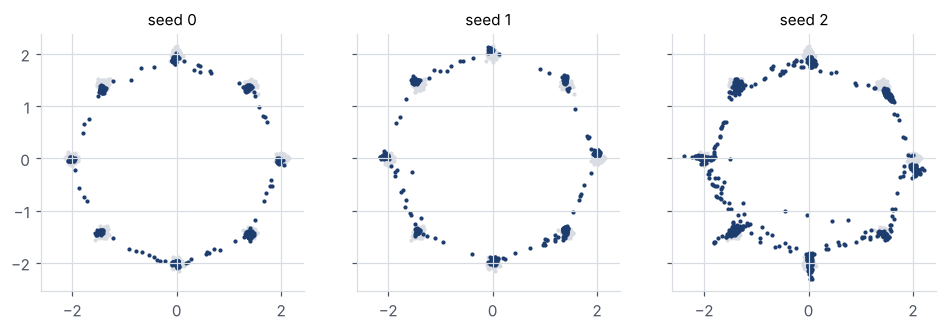

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharex=True, sharey=True)
centres = mode_centers()
for ax, seed in zip(axes, range(3)):
    s = samples_by_seed[seed]
    ax.scatter(X[:800, 0], X[:800, 1], s=3, color=RULE)
    ax.scatter(s[:800, 0], s[:800, 1], s=3, color=NAVY)
    ax.set_title(f"seed {seed}", fontsize=10); ax.set_aspect("equal")
plt.show()

At equilibrium a perfect discriminator cannot tell real from generated and outputs 0.5 everywhere. The printed averages sit near that value, but they bounce around it from step to step, and the same code gives
different sample quality from seed to seed. Part 2 looks at what goes wrong when the game does not settle.